# Early Stroke Risk Prediction Using Machine Learning and Class Rebalancing

## Final Project Implementation

Random Forest, XGBoost, SMOTE and SMOTENC.

SDG 3: Good Health and Well-Being.

Educational prototype, not intended for medical diagnosis.

In [9]:
# Install the required libraries

!pip install -q imbalanced-learn xgboost

In [10]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

In [11]:
# Upload the dataset

from google.colab import files

uploaded = files.upload()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (1).csv


In [12]:
# Read the CSV file
df = pd.read_csv('healthcare-dataset-stroke-data.csv')


df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [13]:
# Check the dataset size

print('Number of rows:', df.shape[0])
print('Number of columns:', df.shape[1])

Number of rows: 5110
Number of columns: 12


In [14]:
# Check column types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [15]:
# Summary of numerical features

df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [16]:
# Check missing values

df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [17]:
# Check duplicate rows

print('Duplicate records:', df.duplicated().sum())

Duplicate records: 0


In [18]:
# Check class imbalance

print('Class distribution:')
print(df['stroke'].value_counts())
print('\nPercentage distribution:')
print(df['stroke'].value_counts(normalize=True) * 100)

Class distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Percentage distribution:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


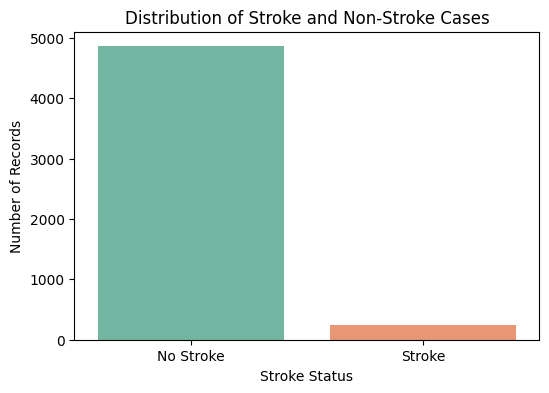

In [19]:
# Plot the target distribution

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='stroke', hue='stroke', palette='Set2', legend=False)
plt.xticks([0, 1], ['No Stroke', 'Stroke'])
plt.title('Distribution of Stroke and Non-Stroke Cases')
plt.xlabel('Stroke Status')
plt.ylabel('Number of Records')
plt.show()

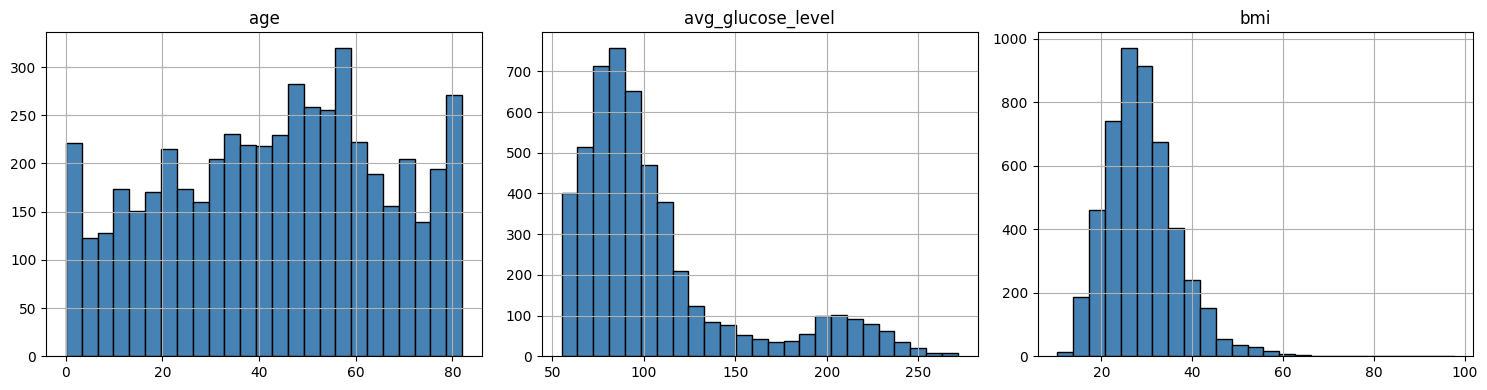

In [20]:
# Plot numerical distributions

df[['age', 'avg_glucose_level', 'bmi']].hist(
    figsize=(15, 4),
    bins=25,
    layout=(1, 3),
    color='steelblue',
    edgecolor='black',
)
plt.tight_layout()
plt.show()

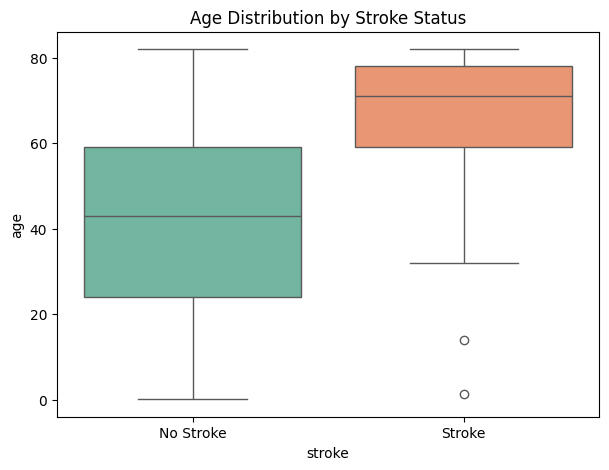

In [21]:
# Compare age across classes

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='stroke', y='age', hue='stroke', palette='Set2', legend=False)
plt.xticks([0, 1], ['No Stroke', 'Stroke'])
plt.title('Age Distribution by Stroke Status')
plt.show()

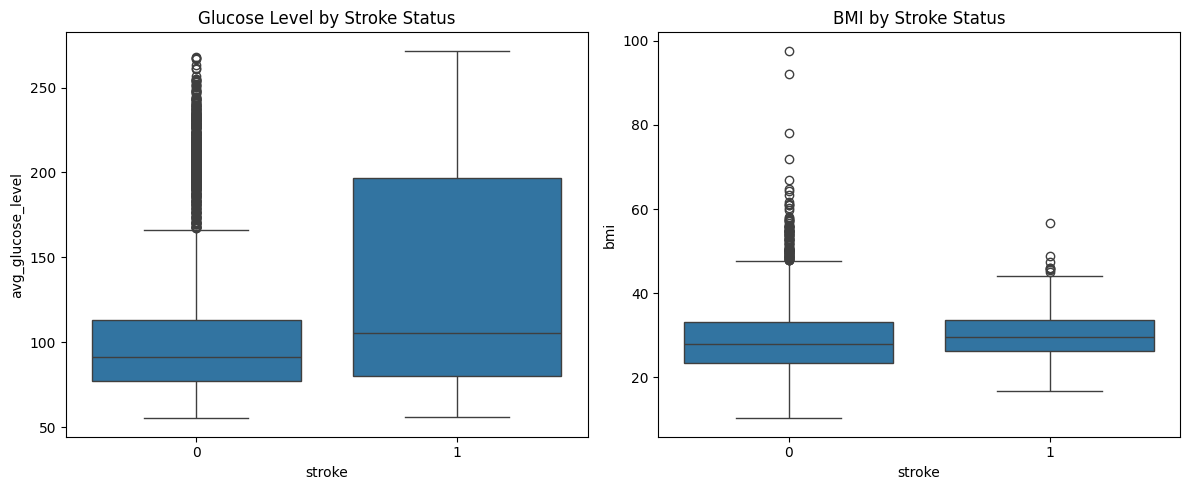

In [22]:
# Compare glucose and BMI

(fig, axes) = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='stroke', y='avg_glucose_level', ax=axes[0])
axes[0].set_title('Glucose Level by Stroke Status')
sns.boxplot(data=df, x='stroke', y='bmi', ax=axes[1])
axes[1].set_title('BMI by Stroke Status')
plt.tight_layout()
plt.show()

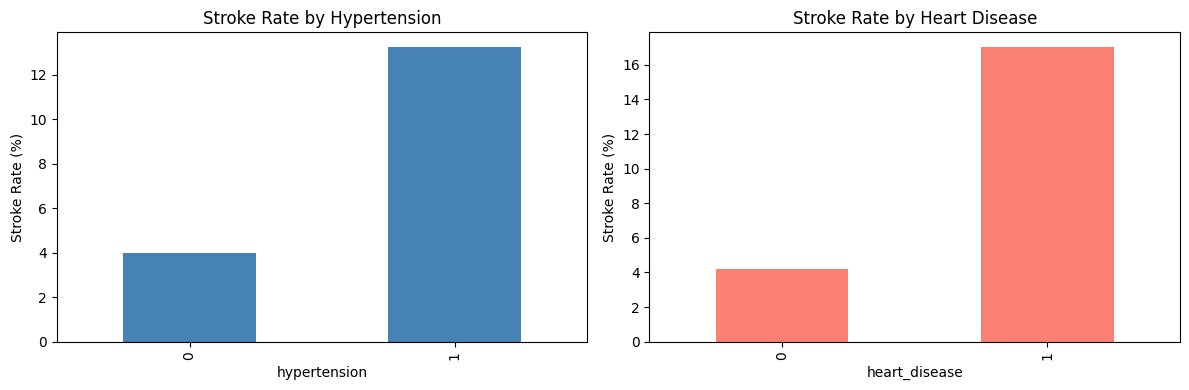

In [23]:
# Compare stroke rates by category

(fig, axes) = plt.subplots(1, 2, figsize=(12, 4))

df.groupby('hypertension')['stroke'].mean().mul(100).plot(
    kind='bar',
    ax=axes[0],
    color='steelblue',
)
axes[0].set_title('Stroke Rate by Hypertension')
axes[0].set_ylabel('Stroke Rate (%)')
df.groupby('heart_disease')['stroke'].mean().mul(100).plot(
    kind='bar',
    ax=axes[1],
    color='salmon',
)
axes[1].set_title('Stroke Rate by Heart Disease')
axes[1].set_ylabel('Stroke Rate (%)')
plt.tight_layout()
plt.show()

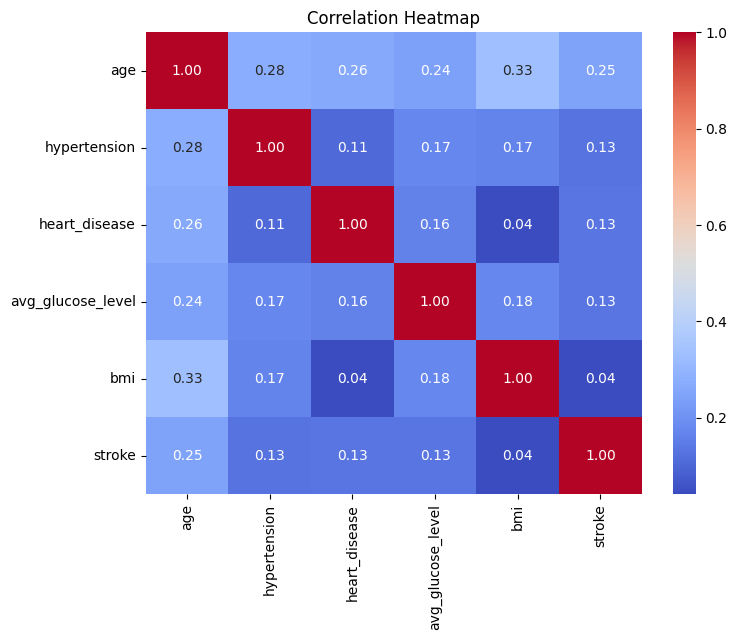

In [24]:
# Check numerical correlations

plt.figure(figsize=(8, 6))
sns.heatmap(
    df.drop(columns=['id']).corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
)
plt.title('Correlation Heatmap')
plt.show()

In [25]:
# Separate inputs and target

X = df.drop(columns=['id', 'stroke'])
y = df['stroke']

print('Input features:', X.shape)
print('Target variable:', y.shape)
X.head()

Input features: (5110, 10)
Target variable: (5110,)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked


In [26]:
# Split data into training, validation and test sets

from sklearn.model_selection import train_test_split

(X_train_full, X_test, y_train_full, y_test) = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

(X_train, X_val, y_train, y_val) = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full,
)

print('Training records:', len(X_train))
print('Validation records:', len(X_val))
print('Testing records:', len(X_test))

Training records: 3066
Validation records: 1022
Testing records: 1022


In [27]:
# Group numerical and categorical columns

numerical_features = ['age', 'avg_glucose_level', 'bmi']
categorical_features = [
    'gender',
    'hypertension',
    'heart_disease',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status',
]

print('Numerical features:', numerical_features)
print('Categorical features:', categorical_features)

Numerical features: ['age', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


In [28]:
# Fill missing numerical values and scale

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

numerical_pipeline = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ],
)

In [29]:
# Fill and encode categorical values

from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ],
)

In [30]:
# Combine preprocessing steps

from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    [
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features),
    ],
)

In [31]:
# Fit preprocessing on training data only

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print('Training shape:', X_train_processed.shape)
print('Validation shape:', X_val_processed.shape)
print('Missing values:', np.isnan(X_train_processed).sum())

Training shape: (3066, 23)
Validation shape: (1022, 23)
Missing values: 0


In [32]:
# Train Random Forest without resampling

from sklearn.ensemble import RandomForestClassifier

rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42)

rf_baseline.fit(X_train_processed, y_train)
print('Random Forest training completed.')

Random Forest training completed.


In [33]:
# Train XGBoost without resampling

from xgboost import XGBClassifier

xgb_baseline = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss',
)

xgb_baseline.fit(X_train_processed, y_train)
print('XGBoost training completed.')

XGBoost training completed.


In [34]:
# Balance training data using SMOTE

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

(X_train_smote, y_train_smote) = smote.fit_resample(X_train_processed, y_train)

print('Before SMOTE:')
print(y_train.value_counts())
print('After SMOTE:')
print(y_train_smote.value_counts())

Before SMOTE:
stroke
0    2917
1     149
Name: count, dtype: int64
After SMOTE:
stroke
0    2917
1    2917
Name: count, dtype: int64


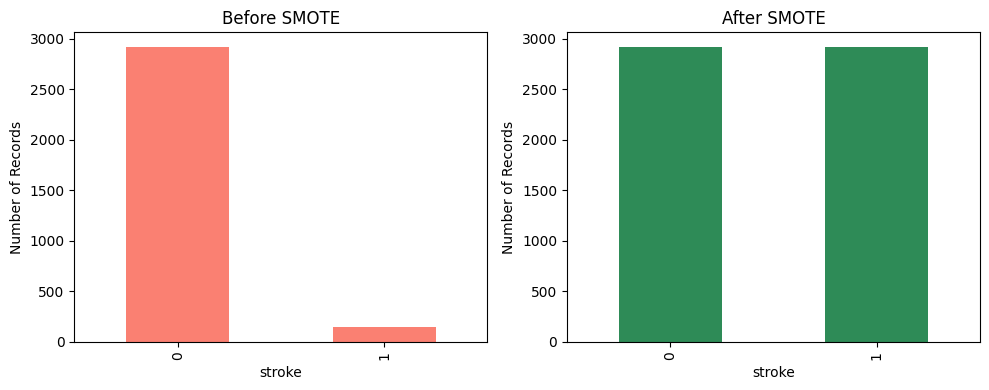

In [35]:
# Compare class counts before and after SMOTE

(fig, axes) = plt.subplots(1, 2, figsize=(10, 4))

y_train.value_counts().sort_index().plot(kind='bar', ax=axes[0], color='salmon')
axes[0].set_title('Before SMOTE')
axes[0].set_ylabel('Number of Records')
y_train_smote.value_counts().sort_index().plot(
    kind='bar',
    ax=axes[1],
    color='seagreen',
)
axes[1].set_title('After SMOTE')
axes[1].set_ylabel('Number of Records')
plt.tight_layout()
plt.show()

In [36]:
# Train Random Forest on balanced data

rf_smote = RandomForestClassifier(n_estimators=100, random_state=42)

rf_smote.fit(X_train_smote, y_train_smote)
print('Random Forest with SMOTE trained.')

Random Forest with SMOTE trained.


In [37]:
# Train XGBoost on balanced data

xgb_smote = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss',
)

xgb_smote.fit(X_train_smote, y_train_smote)
print('XGBoost with SMOTE trained.')

XGBoost with SMOTE trained.


In [38]:
# Prepare mixed features for SMOTENC

smotenc_preprocessor = ColumnTransformer([('num', numerical_pipeline, numerical_features), ('cat', SimpleImputer(strategy='most_frequent'), categorical_features)], verbose_feature_names_out=False).set_output(
    transform='pandas',
)
X_train_nc = smotenc_preprocessor.fit_transform(X_train)
X_val_nc = smotenc_preprocessor.transform(X_val)

X_train_nc.head()

,age,avg_glucose_level,bmi,gender,hypertension,heart_disease,ever_married,work_type,Residence_type,smoking_status
1990,-1.827461,0.134857,-1.343915,Male,0,0,No,children,Urban,Unknown
3840,-1.297185,-0.809394,-0.607144,Female,0,0,No,Private,Urban,formerly smoked
2596,0.691353,-0.602963,0.129627,Female,0,0,Yes,Private,Rural,Unknown
591,0.205266,-0.463883,0.409092,Male,0,0,Yes,Private,Urban,smokes
2975,-0.457580,0.161973,1.819120,Female,0,0,Yes,Private,Rural,never smoked


In [39]:
# Apply SMOTENC to training data

from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(categorical_features=categorical_features, random_state=42)

(X_train_nc_balanced, y_train_nc) = smotenc.fit_resample(X_train_nc, y_train)

print('Before SMOTENC:')
print(y_train.value_counts())
print('After SMOTENC:')
print(y_train_nc.value_counts())

Before SMOTENC:
stroke
0    2917
1     149
Name: count, dtype: int64
After SMOTENC:
stroke
0    2917
1    2917
Name: count, dtype: int64


In [40]:
# Encode categorical features after resampling

nc_encoder = ColumnTransformer(
    [
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
    ],
)
X_train_nc_encoded = nc_encoder.fit_transform(X_train_nc_balanced)
X_val_nc_encoded = nc_encoder.transform(X_val_nc)

print('Training shape:', X_train_nc_encoded.shape)

Training shape: (5834, 23)


In [41]:
# Train XGBoost using SMOTENC data

xgb_smotenc = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss',
)

xgb_smotenc.fit(X_train_nc_encoded, y_train_nc)
print('XGBoost with SMOTENC trained.')

XGBoost with SMOTENC trained.


In [42]:
# Compare models on validation data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

models = {
    'Random Forest': (rf_baseline, X_val_processed),
    'XGBoost': (xgb_baseline, X_val_processed),
    'Random Forest + SMOTE': (rf_smote, X_val_processed),
    'XGBoost + SMOTE': (xgb_smote, X_val_processed),
    'XGBoost + SMOTENC': (xgb_smotenc, X_val_nc_encoded),
}

results = []

for name, (model, data) in models.items():
    predictions = model.predict(data)
    probabilities = model.predict_proba(data)[:, 1]
    results.append(
        {
            'Model': name,
            'Accuracy': accuracy_score(y_val, predictions),
            'Precision': precision_score(y_val, predictions, zero_division=0),
            'Recall': recall_score(y_val, predictions, zero_division=0),
            'F1 Score': f1_score(y_val, predictions, zero_division=0),
            'ROC-AUC': roc_auc_score(y_val, probabilities),
        },
    )

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.9501,0.0000,0.00,0.0000,0.7959
1,XGBoost,0.9530,1.0000,0.04,0.0769,0.8503
2,Random Forest + SMOTE,0.9344,0.0952,0.04,0.0563,0.7877
3,XGBoost + SMOTE,0.8973,0.1519,0.24,0.1860,0.8082
4,XGBoost + SMOTENC,0.8249,0.1475,0.54,0.2318,0.7990


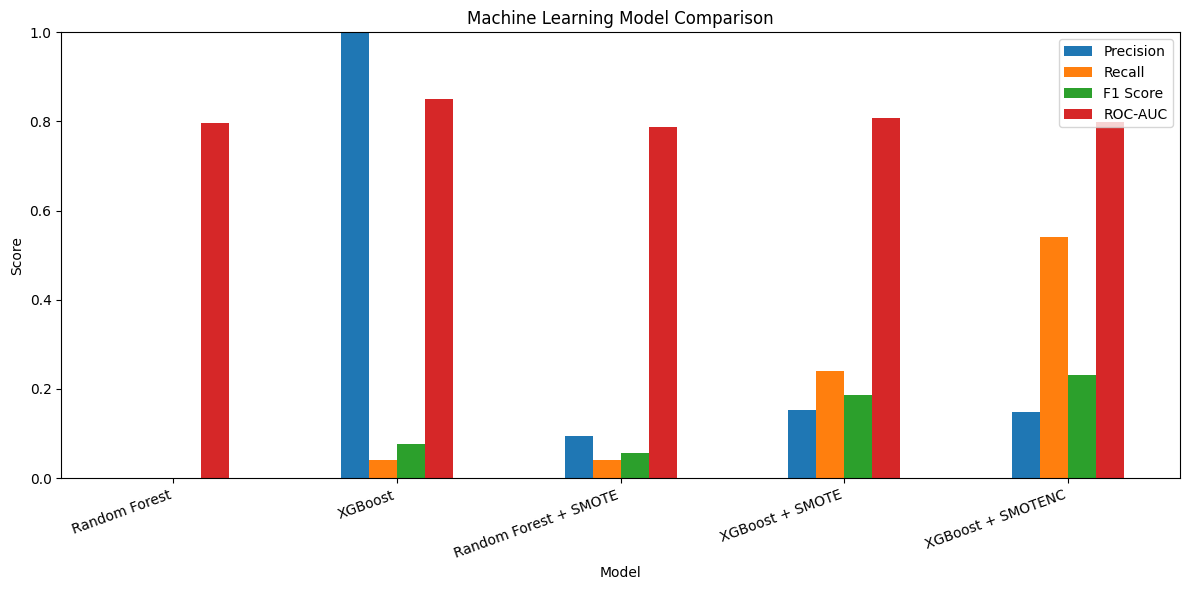

In [43]:
# Plot model comparison

results_df.set_index('Model')[['Precision', 'Recall', 'F1 Score', 'ROC-AUC']].plot(
    kind='bar',
    figsize=(12, 6),
)
plt.title('Machine Learning Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [44]:
# Select model using validation ROC-AUC

best_index = results_df['ROC-AUC'].idxmax()
best_model_name = results_df.loc[best_index, 'Model']
(best_model, best_val_data) = models[best_model_name]

print('Selected Model:', best_model_name)
print('Validation ROC-AUC:', results_df.loc[best_index, 'ROC-AUC'])

Selected Model: XGBoost
Validation ROC-AUC: 0.8503292181069958


In [45]:
# Compare classification thresholds

val_probabilities = best_model.predict_proba(best_val_data)[:, 1]
threshold_results = []

for threshold in np.round(np.arange(0.05, 0.51, 0.05), 2):
    predictions = (val_probabilities >= threshold).astype(int)
    threshold_results.append(
        {
            'Threshold': threshold,
            'Precision': precision_score(y_val, predictions, zero_division=0),
            'Recall': recall_score(y_val, predictions, zero_division=0),
            'F1 Score': f1_score(y_val, predictions, zero_division=0),
        },
    )

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1 Score
0,0.05,0.1541,0.86,0.2614
1,0.10,0.1635,0.52,0.2488
2,0.15,0.1809,0.34,0.2361
3,0.20,0.2564,0.20,0.2247
4,0.25,0.3333,0.10,0.1538
5,0.30,0.4444,0.08,0.1356
6,0.35,0.5000,0.06,0.1071
7,0.40,0.6000,0.06,0.1091
8,0.45,1.0000,0.06,0.1132
9,0.50,1.0000,0.04,0.0769


In [46]:
# Choose a threshold using validation recall and F1

eligible = threshold_df[threshold_df['Recall'] >= 0.7]

if not eligible.empty:
    best_row = eligible.loc[eligible['F1 Score'].idxmax()]
else:
    best_row = threshold_df.loc[threshold_df['Recall'].idxmax()]

best_threshold = float(best_row['Threshold'])

print('Selected threshold:', best_threshold)
print('Validation precision:', best_row['Precision'])
print('Validation recall:', best_row['Recall'])
print('Validation F1 score:', best_row['F1 Score'])

Selected threshold: 0.05
Validation precision: 0.15412186379928317
Validation recall: 0.86
Validation F1 score: 0.2613981762917933


In [47]:
# Evaluate the selected model on test data

from sklearn.metrics import confusion_matrix, classification_report, roc_curve

if best_model_name == 'XGBoost + SMOTENC':
    X_test_nc = smotenc_preprocessor.transform(X_test)
    X_test_final = nc_encoder.transform(X_test_nc)
else:
    X_test_final = preprocessor.transform(X_test)

test_probabilities = best_model.predict_proba(X_test_final)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print('Selected Model:', best_model_name)
print('Threshold:', best_threshold)
print('Accuracy:', accuracy_score(y_test, test_predictions))
print('Precision:', precision_score(y_test, test_predictions, zero_division=0))
print('Recall:', recall_score(y_test, test_predictions))
print('F1 Score:', f1_score(y_test, test_predictions))
print('ROC-AUC:', roc_auc_score(y_test, test_probabilities))
print(classification_report(y_test, test_predictions, zero_division=0))

Selected Model: XGBoost
Threshold: 0.05
Accuracy: 0.7788649706457925
Precision: 0.15625
Recall: 0.8
F1 Score: 0.26143790849673204
ROC-AUC: 0.8469135802469134
              precision    recall  f1-score   support

           0       0.99      0.78      0.87       972
           1       0.16      0.80      0.26        50

    accuracy                           0.78      1022
   macro avg       0.57      0.79      0.57      1022
weighted avg       0.95      0.78      0.84      1022



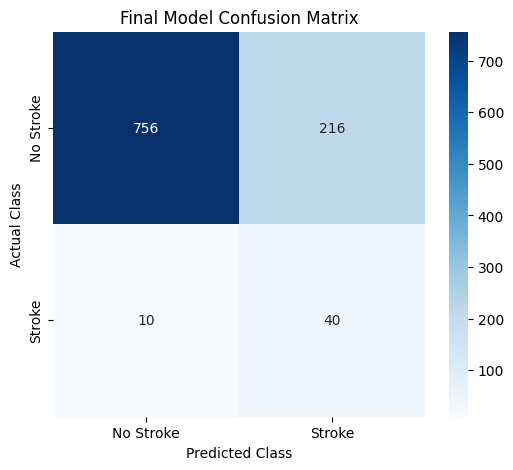

In [48]:
# Plot confusion matrix

cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Stroke', 'Stroke'],
    yticklabels=['No Stroke', 'Stroke'],
)
plt.title('Final Model Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

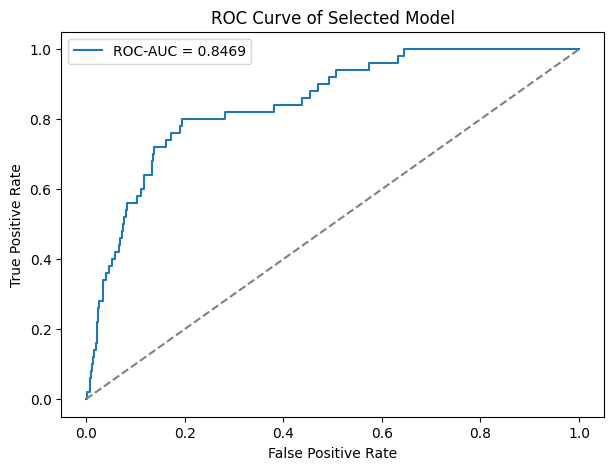

In [49]:
# Plot ROC curve

(fpr, tpr, thresholds) = roc_curve(y_test, test_probabilities)
auc_score = roc_auc_score(y_test, test_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {auc_score:.4f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of Selected Model')
plt.legend()
plt.show()

In [50]:
# Find important features

if best_model_name == 'XGBoost + SMOTENC':
    feature_names = nc_encoder.get_feature_names_out()
else:
    feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame(
    {
        'Feature': feature_names,
        'Importance': best_model.feature_importances_,
    },
)

importance_df['Feature'] = importance_df['Feature'].str.replace('num__', '', regex=False).str.replace(
    'cat__',
    '',
    regex=False,
)
importance_df = importance_df.sort_values(by='Importance', ascending=False)

importance_df.head(10)

,Feature,Importance
0,age,0.221346
12,work_type_Govt_job,0.091460
21,smoking_status_never smoked,0.072026
6,hypertension_0,0.069097
8,heart_disease_0,0.067792
22,smoking_status_smokes,0.061966
1,avg_glucose_level,0.058977
19,smoking_status_Unknown,0.055302
2,bmi,0.053712
10,ever_married_No,0.052764


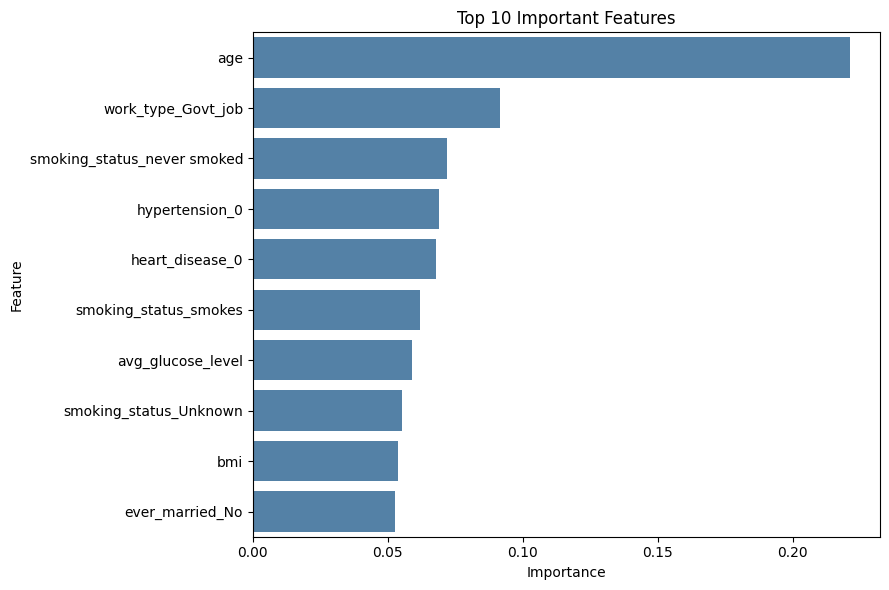

In [51]:
# Plot top ten features

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature',
    color='steelblue',
)
plt.title('Top 10 Important Features')
plt.tight_layout()
plt.show()

In [52]:
# Save model and matching preprocessing

os.makedirs('stroke_model', exist_ok=True)
joblib.dump(best_model, 'stroke_model/model.pkl')
joblib.dump(best_threshold, 'stroke_model/threshold.pkl')

if best_model_name == 'XGBoost + SMOTENC':
    final_preprocessor = Pipeline([('preprocessing', smotenc_preprocessor), ('encoding', nc_encoder)])
else:
    final_preprocessor = preprocessor

joblib.dump(final_preprocessor, 'stroke_model/preprocessor.pkl')
joblib.dump(best_model_name, 'stroke_model/model_name.pkl')
print('Model files saved successfully.')

Model files saved successfully.


In [53]:
# Load saved model files

loaded_model = joblib.load('stroke_model/model.pkl')
loaded_preprocessor = joblib.load('stroke_model/preprocessor.pkl')
loaded_threshold = joblib.load('stroke_model/threshold.pkl')

print('Model loaded successfully.')
print('Decision threshold:', loaded_threshold)

Model loaded successfully.
Decision threshold: 0.05


In [54]:
# Test prediction on a sample record

def predict_stroke(input_data):
    input_df = pd.DataFrame([input_data])
    processed_data = loaded_preprocessor.transform(input_df)
    score = loaded_model.predict_proba(processed_data)[0][1]

    if score >= loaded_threshold:
        prediction = 'Stroke-positive classification'
    else:
        prediction = 'Non-stroke classification'

    return (prediction, round(float(score), 4))

sample = {
    'gender': 'Female',
    'age': 65,
    'hypertension': 1,
    'heart_disease': 0,
    'ever_married': 'Yes',
    'work_type': 'Private',
    'Residence_type': 'Urban',
    'avg_glucose_level': 180,
    'bmi': 30,
    'smoking_status': 'formerly smoked',
}

(prediction, score) = predict_stroke(sample)

print('Model Prediction:', prediction)
print('Model Score:', score)
print('Educational prediction only. Not a medical diagnosis.')

Model Prediction: Stroke-positive classification
Model Score: 0.1139
Educational prediction only. Not a medical diagnosis.


In [55]:
# Download model files

import shutil

shutil.make_archive('stroke_model', 'zip', 'stroke_model')
files.download('stroke_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>